<a href="https://colab.research.google.com/github/NicoleLivesta/ProbstatP11_NicoleLivesta_3TID/blob/main/Probstat_P11_NicoleLivesta_3TID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
from google.colab import files

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving KUISIONER LATIHAN MK STATISTIKA PROBABILITAS (Responses).xlsx to KUISIONER LATIHAN MK STATISTIKA PROBABILITAS (Responses).xlsx
File terbaca: KUISIONER LATIHAN MK STATISTIKA PROBABILITAS (Responses).xlsx


In [3]:
JUMLAH_KOLOM_DEMOGRAFI = 6 # ubah sesuai jumlah kolom demografi pada data

df = pd.read_excel(nama_file)
butir = df.loc[
    :,
    df.columns.astype(str).str.contains(r"\[")
].copy()

print("Jumlah responden :", len(df))
print("Jumlah butir :", butir.shape[1])
print("Data kosong :", int(butir.isna().sum().sum()))

Jumlah responden : 38
Jumlah butir : 27
Data kosong : 0


In [4]:
skala = {
  "Sangat Tidak Setuju (STS)": 1,
  "Tidak Setuju (TS)": 2,
  "Netral (N)": 3,
  "Setuju (S)": 4,
  "Sangat Setuju (SS)": 5,
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_6480/3935969688.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memanfaatkan AI untuk menemukan ide alternatif ketika mengembangkan topik tugas atau projek perkuliahan.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberikan AI],Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,5,5,4,4,5,5,5,1,...,4,4,5,1,5,4,1,1,1,5
1,4,4,5,4,3,4,4,3,1,1,...,4,2,2,2,2,4,5,5,5,5
2,2,4,2,4,4,4,2,4,4,4,...,4,2,4,4,2,2,2,4,4,5
3,4,5,5,4,5,5,5,4,4,4,...,2,1,1,1,1,1,5,5,5,5
4,5,4,5,5,4,4,3,3,1,3,...,4,1,5,5,4,5,5,4,4,5


In [5]:
dimensi = {}
for kolom in butir.columns:
  nama = re.match(r"^(.*?) \[", kolom).group(1)
  dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
  print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 6 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik.: 4 butir
Rsspon emosional: 4 butir


In [6]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
  x = num[daftar]
  total = x.sum(axis=1)
  for i, kolom in enumerate(daftar, 1):
    r, p = stats.pearsonr(x[kolom], total)
    r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
    hasil_validitas.append({
      "Dimensi": nama,
      "Butir": f"B{i}",
      "r hitung": round(r, 3),
      "Corrected r": round(r_koreksi, 3),
      "p-value": round(p, 4),
      "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
    })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 38 | r tabel (α=0,05; df=36) = 0.320


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.723,0.547,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.393,0.260,0.0145,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.428,0.257,0.0074,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.470,0.240,0.0029,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.703,0.523,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.739,0.627,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.738,0.550,0.0000,Valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.651,0.516,0.0000,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.750,0.567,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.643,0.430,0.0000,Valid


In [7]:
def cronbach_alpha(x):
  k = x.shape[1]
  return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
  return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
    else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
  x = num[daftar]
  a = cronbach_alpha(x)
  hasil_reliabilitas.append({
    "Dimensi": nama,
    "Jumlah butir": len(daftar),
    "Cronbach's alpha": round(a, 3),
    "Kategori": kategori(a),
  })
  for i, kolom in enumerate(daftar, 1):
    if len(daftar) > 2:
      alpha_dihapus.append({
        "Dimensi": nama,
        "Butir": f"B{i}",
        "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)),
      3),
  })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.713,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,6,0.728,Reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.754,Reliabel
3,Prokrastinasi akademik.,4,0.817,Baik
4,Rsspon emosional,4,0.813,Baik


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.645
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.714
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.715
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.728
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.653
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.639
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.644
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.683
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.656
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.701


In [8]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"],
how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
  gabung.to_excel(w, sheet_name="Validitas", index=False)
  tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.pyplot as plt

In [9]:
df = pd.read_excel(nama_file)
print("Responden :", len(df), "| Butir :", butir.shape[1])
print("Data kosong :", int(butir.isna().sum().sum()))
print("Baris duplikat :", int(df.duplicated().sum()))
print(df["Kelas"].value_counts().to_dict(), df["Jenis Kelamin"].value_counts().to_dict())

Responden : 38 | Butir : 27
Data kosong : 0
Baris duplikat : 0
{'3 TI D': 38} {'Laki-laki': 25, 'Perempuan': 13}


In [11]:
rapi = {}
for nama in dimensi:
    n = nama.strip().rstrip(".")
    n = n.replace("Rsspon", "Respons").replace("Psikologis", "psikologis")
    rapi[nama] = n

In [12]:
skor = pd.DataFrame({rapi[nm]: num[d].sum(axis=1) for nm, d in dimensi.items()})
jml_butir = {rapi[nm]: len(d) for nm, d in dimensi.items()}

In [13]:
desk = pd.DataFrame({
    "Jumlah butir": pd.Series(jml_butir),
    "Mean": skor.mean(),
    "Median": skor.median(),
    "Std. deviasi": skor.std(ddof=1),
    "Varians": skor.var(ddof=1),
})
desk["Rata-rata per butir"] = desk["Mean"] / desk["Jumlah butir"]
display(desk.round(3))

,Jumlah butir,Mean,Median,Std. deviasi,Varians,Rata-rata per butir
Penggunaan AI pada tugas atau projek kuliah,7,30.184,31.0,3.439,11.830,4.312
Aspek psikologis penggunaan AI pada tugas atau projek kuliah,6,20.763,22.0,5.232,27.375,3.461
Kebiasaan penggunaan teknologi digital,6,17.289,17.5,5.756,33.130,2.882
Prokrastinasi akademik,4,11.526,12.0,4.746,22.526,2.882
Respons emosional,4,16.079,18.0,4.116,16.940,4.020


In [14]:
sk_ku = pd.DataFrame({"Skewness": skor.skew(), "Kurtosis (excess)": skor.kurt()})
display(sk_ku.round(3))

,Skewness,Kurtosis (excess)
Penggunaan AI pada tugas atau projek kuliah,-1.128,0.875
Aspek psikologis penggunaan AI pada tugas atau projek kuliah,-0.559,-0.855
Kebiasaan penggunaan teknologi digital,0.132,-0.432
Prokrastinasi akademik,0.205,-1.010
Respons emosional,-1.412,1.093


In [15]:
sw = []
for k in skor.columns:
    W, p = stats.shapiro(skor[k])
    sw.append({"Dimensi": k, "W": round(W, 3), "p-value": round(p, 4),
               "Keputusan": "Ada penyimpangan signifikan" if p <= 0.05
                            else "Tidak ada penyimpangan signifikan"})
display(pd.DataFrame(sw))

,Dimensi,W,p-value,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,0.896,0.0020,Ada penyimpangan signifikan
1,Aspek psikologis penggunaan AI pada tugas atau...,0.922,0.0113,Ada penyimpangan signifikan
2,Kebiasaan penggunaan teknologi digital,0.963,0.2455,Tidak ada penyimpangan signifikan
3,Prokrastinasi akademik,0.953,0.1140,Tidak ada penyimpangan signifikan
4,Respons emosional,0.811,0.0000,Ada penyimpangan signifikan


,STS,TS,N,S,SS,Total jawaban
Penggunaan AI pada tugas atau projek kuliah,4,9,9,122,122,266
Aspek psikologis penggunaan AI pada tugas atau projek kuliah,29,38,20,81,60,228
Kebiasaan penggunaan teknologi digital,54,64,7,61,42,228
Prokrastinasi akademik,34,46,8,32,32,152
Respons emosional,13,15,1,50,73,152


,STS,TS,N,S,SS
Penggunaan AI pada tugas atau projek kuliah,1.5,3.4,3.4,45.9,45.9
Aspek psikologis penggunaan AI pada tugas atau projek kuliah,12.7,16.7,8.8,35.5,26.3
Kebiasaan penggunaan teknologi digital,23.7,28.1,3.1,26.8,18.4
Prokrastinasi akademik,22.4,30.3,5.3,21.1,21.1
Respons emosional,8.6,9.9,0.7,32.9,48.0


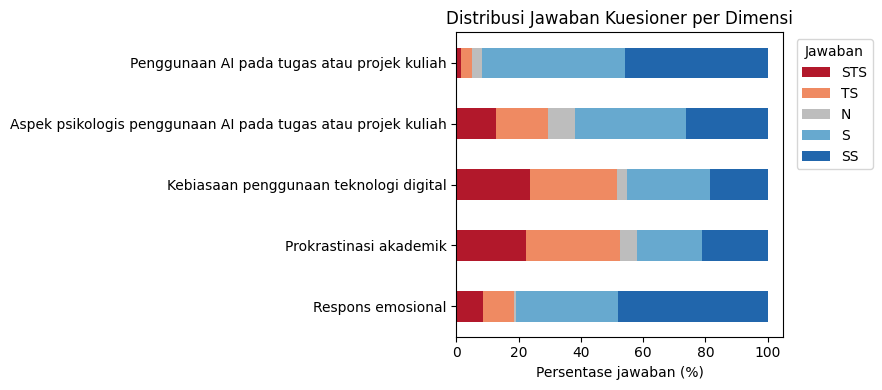

In [16]:
label = {1: "STS", 2: "TS", 3: "N", 4: "S", 5: "SS"}
dist = {}
for nm, d in dimensi.items():
    v = pd.Series(num[d].values.ravel()).value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    dist[rapi[nm]] = v.rename(index=label)
dist = pd.DataFrame(dist).T
dist["Total jawaban"] = dist.sum(axis=1)
display(dist)
display((dist[["STS", "TS", "N", "S", "SS"]].div(dist["Total jawaban"], axis=0) * 100).round(1))

pct = dist[["STS", "TS", "N", "S", "SS"]].div(dist["Total jawaban"], axis=0) * 100
warna = ["#b2182b", "#ef8a62", "#bdbdbd", "#67a9cf", "#2166ac"]
ax = pct.plot(kind="barh", stacked=True, figsize=(9, 4), color=warna)
ax.set_xlabel("Persentase jawaban (%)")
ax.set_title("Distribusi Jawaban Kuesioner per Dimensi")
ax.invert_yaxis()
plt.legend(title="Jawaban", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("distribusi_jawaban.png", dpi=200)
plt.show()

In [17]:
nm_psi = list(dimensi.keys())[1]
d_psi = dimensi[nm_psi]
x_sebelum = num[d_psi]
kolom_b6 = d_psi[5]
x_sesudah = x_sebelum.drop(columns=kolom_b6)
alpha_sebelum = cronbach_alpha(x_sebelum)
alpha_sesudah = cronbach_alpha(x_sesudah)
print("Dimensi:", rapi[nm_psi])
print("Jumlah butir sebelum:", x_sebelum.shape[1])
print("Jumlah butir sesudah:", x_sesudah.shape[1])
print(f"Alpha sebelum B6 dihapus : {alpha_sebelum:.3f}")
print(f"Alpha sesudah B6 dihapus : {alpha_sesudah:.3f}")

total_sesudah = x_sesudah.sum(axis=1)
hasil_ulang = []
for i, kolom in enumerate(x_sesudah.columns, 1):
    r_hitung, p_value = stats.pearsonr(
        x_sesudah[kolom], total_sesudah
    )

    corrected_r, _ = stats.pearsonr(
        x_sesudah[kolom],
        total_sesudah - x_sesudah[kolom]
    )

    hasil_ulang.append({
        "Butir": f"B{i}",
        "r hitung": round(r_hitung, 3),
        "Corrected r": round(corrected_r, 3),
        "p-value": round(p_value, 4),
        "Valid r hitung": "Valid" if r_hitung > r_tabel else "Tidak valid",
        "Valid Corrected r": (
            "Memenuhi" if corrected_r >= 0.30 else "Tidak memenuhi"
        )
    })
tabel_ulang = pd.DataFrame(hasil_ulang)
display(tabel_ulang)

Dimensi: Aspek psikologis penggunaan AI pada tugas atau projek kuliah
Jumlah butir sebelum: 6
Jumlah butir sesudah: 5
Alpha sebelum B6 dihapus : 0.728
Alpha sesudah B6 dihapus : 0.763


,Butir,r hitung,Corrected r,p-value,Valid r hitung,Valid Corrected r
0,B1,0.630,0.479,0.0,Valid,Memenuhi
1,B2,0.748,0.547,0.0,Valid,Memenuhi
2,B3,0.712,0.509,0.0,Valid,Memenuhi
3,B4,0.711,0.542,0.0,Valid,Memenuhi
4,B5,0.785,0.612,0.0,Valid,Memenuhi


In [18]:
s = num.sample(20, random_state=1)
n2 = len(s)
df2 = n2 - 2
t2 = stats.t.ppf(0.975, df2)
r_tabel2 = t2 / np.sqrt(df2 + t2**2)
print("Jumlah responden:", n2)
print("Derajat bebas:", df2)
print(f"r tabel (α = 0,05): {r_tabel2:.3f}")

hasil20 = []
for nm, daftar in dimensi.items():
    x = s[daftar]
    total = x.sum(axis=1)

    for i, kolom in enumerate(daftar, 1):
        r_hitung, p_value = stats.pearsonr(
            x[kolom], total
        )

        corrected_r, _ = stats.pearsonr(
            x[kolom], total - x[kolom]
        )

        hasil20.append({
            "Dimensi": rapi[nm],
            "Butir": f"B{i}",
            "r hitung": round(r_hitung, 3),
            "Corrected r": round(corrected_r, 3),
            "p-value": round(p_value, 4),
            "Keterangan": (
                "Valid" if r_hitung > r_tabel2
                else "Tidak valid"
            )
        })

h20 = pd.DataFrame(hasil20)
display(h20)
jumlah_valid = (h20["Keterangan"] == "Valid").sum()
jumlah_corrected = (h20["Corrected r"] >= 0.30).sum()
print(f"Butir valid berdasarkan r hitung: {jumlah_valid} dari {len(h20)}")
print(
    "Butir memenuhi Corrected r >= 0,30:",
    jumlah_corrected, "dari", len(h20)
)

Jumlah responden: 20
Derajat bebas: 18
r tabel (α = 0,05): 0.444


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.625,0.447,0.0032,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.573,0.474,0.0083,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.672,0.538,0.0012,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.619,0.413,0.0036,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.679,0.512,0.0010,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.782,0.707,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.652,0.426,0.0018,Valid
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.832,0.755,0.0000,Valid
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.690,0.496,0.0008,Valid
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.652,0.494,0.0018,Valid


Butir valid berdasarkan r hitung: 27 dari 27
Butir memenuhi Corrected r >= 0,30: 27 dari 27
